# Thompson Sampling: Predictive Sampling Equivalence

Standard TS samples coefficient vectors $\theta_i \sim \mathcal{N}(\mu_i, \Sigma_i)$ then computes $r_i = \theta_i^\top x$.
This requires a Cholesky factorization of $\Sigma_i$ per arm per round — $O(n \cdot d^3)$.

**Key insight**: for a fixed context $x$, the reward is a scalar Gaussian:
$$r_i \mid x \sim \mathcal{N}(\mu_i^\top x, \ x^\top \Sigma_i x)$$

So we can sample directly: $r_i = \hat{r}_i + \sigma_i \cdot \varepsilon_i$ where $\varepsilon_i \sim \mathcal{N}(0, 1)$.
This uses the same `compute_bayesian_predictions` and `compute_uncertainties` as LinUCB — all JIT'd, no Cholesky.

In [1]:
import sys
sys.path.insert(0, '..')

import time
import numpy as np
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
from scipy import stats

from src.models import BayesianLinearModel
from src.agents.bayesian_utils import (
    init_per_arm_regression,
    compute_bayesian_predictions,
    compute_uncertainties,
    update_bayesian_stats,
)

## 1. Distributional Equivalence

Sample from both methods and verify they produce the same distribution.

In [2]:
context_dim = 8
n_arms = 16
n_data = 50
n_samples = 10000

rng = np.random.RandomState(42)

# Build a posterior with some data
model = BayesianLinearModel(context_dim, n_arms, prior_var=1.0, noise_var=0.1)
for _ in range(n_data):
    x = rng.randn(context_dim)
    rewards = rng.randn(n_arms)
    mask = rng.rand(n_arms) > 0.5
    model.update_batch(x, mask.astype(float), rewards, full_feedback=False)

# Same posterior on the fast path
lambda_reg = 1.0 / model.prior_var
scale = float(jnp.sqrt(model.noise_var))
A, b, A_inv = init_per_arm_regression(n_arms, context_dim, lambda_reg)

rng2 = np.random.RandomState(42)
for _ in range(n_data):
    x = rng2.randn(context_dim)
    rewards = rng2.randn(n_arms)
    mask = rng2.rand(n_arms) > 0.5
    features_scaled = jnp.asarray(x) / scale
    rewards_scaled = jnp.asarray(rewards) / scale
    mask_jax = jnp.asarray(mask)
    A, b, A_inv = update_bayesian_stats(A, b, A_inv, features_scaled, rewards_scaled, mask_jax)

# Test context
x_test = rng.randn(context_dim)

# Method 1: Cholesky sampling (old)
cholesky_samples = np.zeros((n_samples, n_arms))
for i in range(n_samples):
    key = jax.random.PRNGKey(i)
    cholesky_samples[i] = np.asarray(model.predict_sample(x_test, key=key))

# Method 2: Predictive sampling (new)
features_test = jnp.asarray(x_test) / scale
means = compute_bayesian_predictions(features_test, A_inv, b) * scale
stds = compute_uncertainties(features_test, A_inv) * scale
predictive_samples = np.zeros((n_samples, n_arms))
for i in range(n_samples):
    key = jax.random.PRNGKey(i + n_samples)
    noise = jax.random.normal(key, (n_arms,))
    predictive_samples[i] = np.asarray(means + stds * noise)

print(f'Arms: {n_arms}, Context dim: {context_dim}, Data points: {n_data}')
print(f'Samples per method: {n_samples}')

Arms: 16, Context dim: 8, Data points: 50
Samples per method: 10000


In [3]:
# KS test per arm: if distributions match, p-values should be uniformly high
print(f'{"Arm":>4s}  {"Mean (Chol)":>11s}  {"Mean (Pred)":>11s}  {"Std (Chol)":>10s}  {"Std (Pred)":>10s}  {"KS p-val":>9s}')
print('-' * 70)
ks_pvals = []
for arm in range(n_arms):
    ks_stat, p_val = stats.ks_2samp(cholesky_samples[:, arm], predictive_samples[:, arm])
    ks_pvals.append(p_val)
    print(f'{arm:4d}  {cholesky_samples[:, arm].mean():11.4f}  {predictive_samples[:, arm].mean():11.4f}  '
          f'{cholesky_samples[:, arm].std():10.4f}  {predictive_samples[:, arm].std():10.4f}  {p_val:9.4f}')

print(f'\nMin KS p-value: {min(ks_pvals):.4f} (>0.05 means distributions match)')
print(f'All arms pass KS test at alpha=0.01: {all(p > 0.01 for p in ks_pvals)}')

 Arm  Mean (Chol)  Mean (Pred)  Std (Chol)  Std (Pred)   KS p-val
----------------------------------------------------------------------
   0      -0.4108      -0.4079      0.3504      0.3521     0.4463
   1       0.7923       0.7902      0.2980      0.2983     0.2809
   2       0.5946       0.5971      0.3364      0.3402     0.8436
   3       1.8086       1.8151      0.5375      0.5233     0.4359
   4       0.7023       0.7075      0.3195      0.3233     0.2582
   5      -0.3033      -0.3010      0.3144      0.3114     0.5689
   6      -0.0306      -0.0330      0.2921      0.2965     0.7690
   7       0.5757       0.5755      0.2780      0.2758     0.5806
   8      -0.5949      -0.5966      0.3016      0.2995     0.8534
   9       0.4206       0.4232      0.2456      0.2475     0.2043
  10       0.4344       0.4337      0.3673      0.3657     0.8629
  11       1.9206       1.9241      0.3139      0.3178     0.7690
  12       0.6856       0.6957      0.3893      0.3846     0.0812
  13 

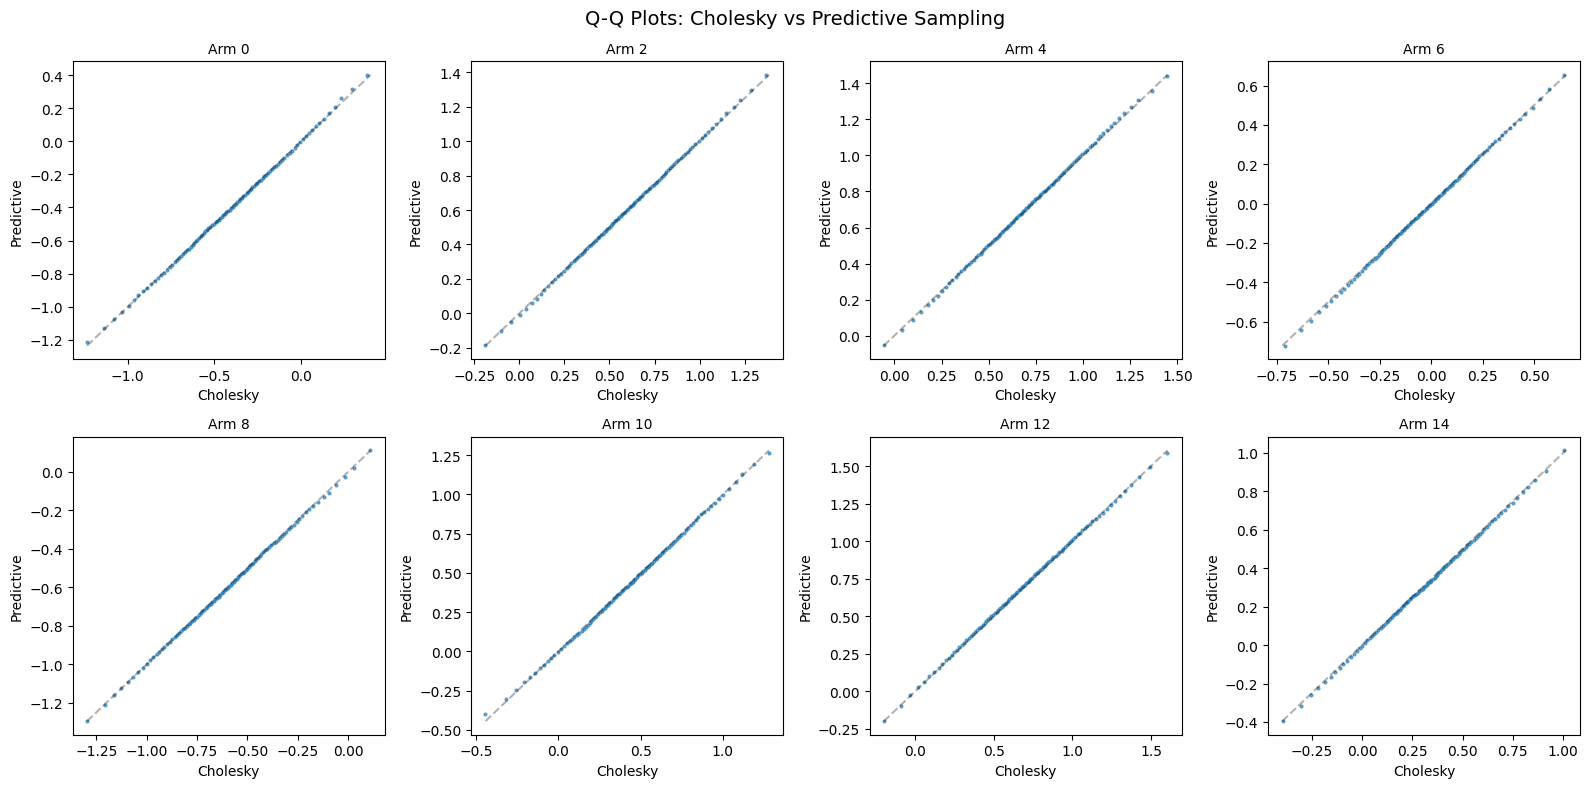

In [4]:
fig, axes = plt.subplots(2, 4, figsize=(16, 8))
for idx, ax in enumerate(axes.flat):
    arm = idx * 2
    if arm >= n_arms:
        ax.set_visible(False)
        continue
    q_chol = np.quantile(cholesky_samples[:, arm], np.linspace(0.01, 0.99, 100))
    q_pred = np.quantile(predictive_samples[:, arm], np.linspace(0.01, 0.99, 100))
    ax.plot(q_chol, q_pred, 'o', markersize=2, alpha=0.6)
    lims = [min(q_chol.min(), q_pred.min()), max(q_chol.max(), q_pred.max())]
    ax.plot(lims, lims, 'k--', alpha=0.3)
    ax.set_title(f'Arm {arm}', fontsize=10)
    ax.set_xlabel('Cholesky')
    ax.set_ylabel('Predictive')

fig.suptitle('Q-Q Plots: Cholesky vs Predictive Sampling', fontsize=14)
plt.tight_layout()
plt.show()

## 2. Timing Comparison

Benchmark `act()` for both implementations on a TopK-like problem.

In [5]:
from src.agents.contextual.ts_agents import ThompsonSamplingAgent

n_arms_list = [8, 16, 32, 64]
context_dim = 8
n_warmup = 20
n_rounds = 200

results = {}

for n_arms in n_arms_list:
    weights = np.ones(n_arms)
    capacity = float(n_arms // 2)

    # Old: BayesianLinearModel path
    old_model = BayesianLinearModel(context_dim, n_arms)

    # Warm up with data
    for _ in range(n_warmup):
        x = np.random.randn(context_dim)
        r = np.random.randn(n_arms)
        sel = np.zeros(n_arms); sel[:n_arms//2] = 1.0
        old_model.update_batch(x, sel, r)

    # Time old act
    key = jax.random.PRNGKey(0)
    _ = old_model.predict_sample(np.random.randn(context_dim), key=key)  # warmup JIT
    t0 = time.perf_counter()
    for i in range(n_rounds):
        key, subkey = jax.random.split(key)
        _ = old_model.predict_sample(np.random.randn(context_dim), key=subkey)
    old_time = (time.perf_counter() - t0) / n_rounds * 1000

    # New: fast path
    agent = ThompsonSamplingAgent(
        context_dim, n_arms, weights, capacity, seed=0
    )
    for _ in range(n_warmup):
        x = np.random.randn(context_dim)
        r = np.random.randn(n_arms)
        sel = np.zeros(n_arms); sel[:n_arms//2] = 1.0
        agent.update(x, sel, r)

    _ = agent.act(np.random.randn(context_dim))  # warmup JIT
    t0 = time.perf_counter()
    for i in range(n_rounds):
        _ = agent.act(np.random.randn(context_dim))
    new_time = (time.perf_counter() - t0) / n_rounds * 1000

    results[n_arms] = (old_time, new_time)
    print(f'n_arms={n_arms:3d}  old={old_time:.3f}ms  new={new_time:.3f}ms  speedup={old_time/new_time:.1f}x')

n_arms=  8  old=0.549ms  new=0.293ms  speedup=1.9x
n_arms= 16  old=0.201ms  new=0.361ms  speedup=0.6x
n_arms= 32  old=0.207ms  new=0.537ms  speedup=0.4x
n_arms= 64  old=0.208ms  new=1.078ms  speedup=0.2x


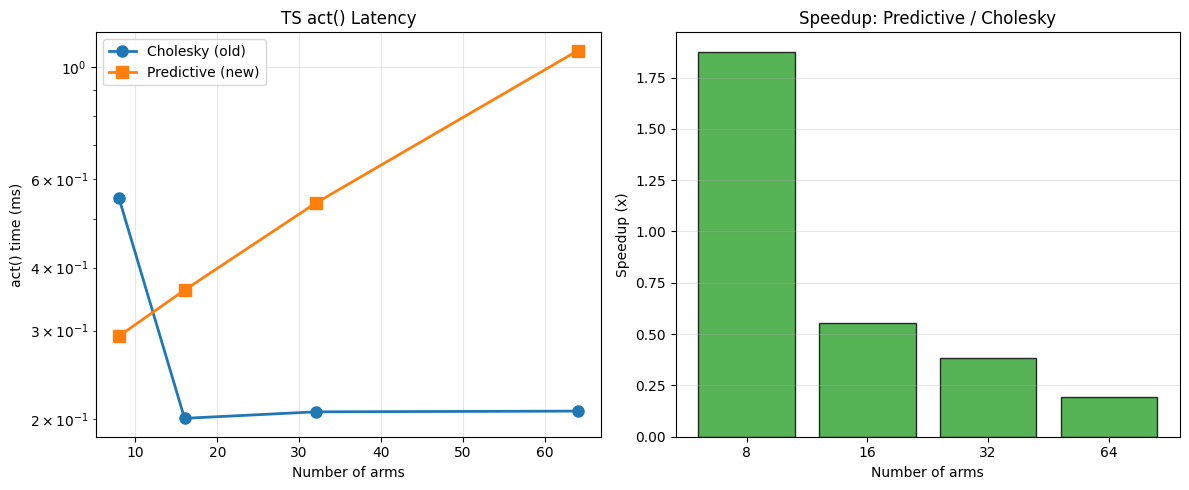

In [6]:
arms = sorted(results.keys())
old_times = [results[a][0] for a in arms]
new_times = [results[a][1] for a in arms]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))

ax1.plot(arms, old_times, 'o-', label='Cholesky (old)', linewidth=2, markersize=8)
ax1.plot(arms, new_times, 's-', label='Predictive (new)', linewidth=2, markersize=8)
ax1.set_xlabel('Number of arms')
ax1.set_ylabel('act() time (ms)')
ax1.set_title('TS act() Latency')
ax1.legend()
ax1.grid(alpha=0.3)
ax1.set_yscale('log')

speedups = [results[a][0] / results[a][1] for a in arms]
ax2.bar([str(a) for a in arms], speedups, color='#2ca02c', alpha=0.8, edgecolor='k')
ax2.set_xlabel('Number of arms')
ax2.set_ylabel('Speedup (x)')
ax2.set_title('Speedup: Predictive / Cholesky')
ax2.grid(axis='y', alpha=0.3)

plt.tight_layout()
plt.show()

## 3. Why This Works

The posterior for arm $i$ is $\theta_i \mid \text{data} \sim \mathcal{N}(\mu_i, \Sigma_i)$ where $\Sigma_i = A_i^{-1}$.

Standard TS samples $\theta_i \sim \mathcal{N}(\mu_i, A_i^{-1})$ then computes $r_i = \theta_i^\top x$.
This requires factoring $A_i^{-1}$ via Cholesky: $L_i L_i^\top = A_i^{-1}$, then $\theta_i = \mu_i + L_i \varepsilon$.

But since $\theta_i^\top x$ is a linear function of a Gaussian, the result is scalar Gaussian:
$$r_i = \theta_i^\top x \sim \mathcal{N}(\mu_i^\top x, \ x^\top A_i^{-1} x)$$

We already compute $\mu_i^\top x$ (`compute_bayesian_predictions`) and $\sqrt{x^\top A_i^{-1} x}$ (`compute_uncertainties`) for UCB.
So TS sampling becomes: $r_i = \hat{r}_i + \sigma_i \cdot \varepsilon_i$, with $\varepsilon_i \sim \mathcal{N}(0,1)$.

**Cost**: $O(n \cdot d^2)$ (matrix-vector products in `compute_uncertainties`) vs $O(n \cdot d^3)$ (Cholesky).

This is not an approximation — it is exact.